In [2]:
import pandas as pd
import numpy as np

In [3]:
client = pd.read_csv("clients.csv", sep=";", decimal=",")
interaction = pd.read_csv("interactions_12_mois.csv", sep=";", decimal=",")

In [4]:
client.shape

(4012, 11)

In [5]:
client.head()

,ID_Client,Date_Ouverture_Compte,Age,Segment,Type_Carte,Nb_Produits,Frais_Mensuels_EUR,Revenu_Annuel_EUR,Solde_Moyen_EUR,Abonnement_Digital,Client_Parti
0,C200281,02/03/2014,20,Particulier,Gold,1,5.09,25781.0,6549.50,Oui,Non
1,C202906,24/06/2023,78,Particulier,Premier,2,5.71,35562.0,5093.42,Oui,Non
2,C203345,16/07/2023,81,Particulier,Classic,1,13.20,30277.0,14566.63,Oui,Non
3,C202965,02/12/2008,83,Particulier,Gold,1,1.32,72358.0,12713.61,Oui,Non
4,C202453,29/03/2006,53,Particulier,Gold,2,8.17,20629.0,6921.41,Oui,Non


In [6]:
client.describe()

,Age,Nb_Produits,Frais_Mensuels_EUR,Revenu_Annuel_EUR,Solde_Moyen_EUR
count,4012.000000,4012.000000,4012.000000,3861.000000,4012.000000
mean,51.564307,2.241027,5.197989,40653.844341,8275.736064
std,19.709283,1.154477,3.435764,19436.876187,12276.470818
min,18.000000,1.000000,0.000000,12000.000000,119.580000
25%,34.000000,1.000000,2.500000,27035.000000,2194.550000
50%,52.000000,2.000000,4.435000,36521.000000,4584.435000
75%,69.000000,3.000000,6.480000,49965.000000,9449.937500
max,85.000000,5.000000,14.640000,214077.000000,251380.730000


In [7]:
client = client.drop_duplicates()
client.shape

(4000, 11)

In [8]:
client["Client_Parti"] = client["Client_Parti"].map({"Oui": 1, "Non": 0})
print(client["Client_Parti"].value_counts(dropna=False))
print(client["Client_Parti"].value_counts(normalize=True))

Client_Parti
0    3516
1     484
Name: count, dtype: int64
Client_Parti
0    0.879
1    0.121
Name: proportion, dtype: float64


In [9]:
# Conversion du texte en vraie date (format français jour/mois/année)
client["Date_Ouverture_Compte"] = pd.to_datetime(client["Date_Ouverture_Compte"], format="%d/%m/%Y")

# Date de référence : octobre 2026
ref_annee, ref_mois = 2026, 10

client["Anciennete_Mois"] = (
    (ref_annee - client["Date_Ouverture_Compte"].dt.year) * 12
    + (ref_mois - client["Date_Ouverture_Compte"].dt.month)
)

client.head()

,ID_Client,Date_Ouverture_Compte,Age,Segment,Type_Carte,Nb_Produits,Frais_Mensuels_EUR,Revenu_Annuel_EUR,Solde_Moyen_EUR,Abonnement_Digital,Client_Parti,Anciennete_Mois
0,C200281,2014-03-02,20,Particulier,Gold,1,5.09,25781.0,6549.50,Oui,0,151
1,C202906,2023-06-24,78,Particulier,Premier,2,5.71,35562.0,5093.42,Oui,0,40
2,C203345,2023-07-16,81,Particulier,Classic,1,13.20,30277.0,14566.63,Oui,0,39
3,C202965,2008-12-02,83,Particulier,Gold,1,1.32,72358.0,12713.61,Oui,0,214
4,C202453,2006-03-29,53,Particulier,Gold,2,8.17,20629.0,6921.41,Oui,0,247


In [10]:
interaction.head()

,ID_Client,Date_Interaction,Type_Interaction,Note_Satisfaction
0,C203494,06/04/2026,Connexion appli,NaN
1,C203394,19/01/2026,Connexion appli,NaN
2,C201694,10/11/2025,Connexion appli,NaN
3,C203295,16/12/2025,Connexion appli,NaN
4,C200506,11/02/2026,Connexion appli,NaN


In [11]:
interaction = pd.read_csv("interactions_12_mois.csv", sep=";", decimal=",")
interaction["Date_Interaction"] = pd.to_datetime(interaction["Date_Interaction"], format="%d/%m/%Y")
date_fin = pd.Timestamp("2026-06-30")

# 1. Nombre d'interactions par type (une colonne par type)
comptages = pd.crosstab(interaction["ID_Client"], interaction["Type_Interaction"])
comptages.columns = ["Nb_" + c.replace(" ", "_") for c in comptages.columns]

# 2. Satisfaction moyenne et récence
autres = interaction.groupby("ID_Client").agg(
    Note_Moyenne=("Note_Satisfaction", "mean"),
    Jours_Depuis_Derniere=("Date_Interaction", lambda d: (date_fin - d.max()).days),
)

# 3. Tendance des connexions : 3 derniers mois comparés aux 9 mois précédents
conn = interaction[interaction["Type_Interaction"] == "Connexion appli"]
recent = conn[conn["Date_Interaction"] >= "2026-04-01"].groupby("ID_Client").size()
ancien = conn[conn["Date_Interaction"] < "2026-04-01"].groupby("ID_Client").size()
tendance = pd.DataFrame({"Conn_3_Derniers_Mois": recent, "Conn_Moy_3_Mois_Avant": ancien / 3}).fillna(0)
tendance["Evolution_Connexions"] = (tendance["Conn_3_Derniers_Mois"] + 1) / (tendance["Conn_Moy_3_Mois_Avant"] + 1)

# Assemblage : une ligne par client
resume = comptages.join(autres).join(tendance).reset_index()
print(resume.shape)
resume.head()

(3920, 10)


,ID_Client,Nb_Appel_service_client,Nb_Connexion_appli,Nb_Réclamation,Nb_Visite_agence,Note_Moyenne,Jours_Depuis_Derniere,Conn_3_Derniers_Mois,Conn_Moy_3_Mois_Avant,Evolution_Connexions
0,C200001,2,37,0,0,2.5,19,9.0,9.333333,0.967742
1,C200002,0,63,2,2,2.0,7,6.0,19.000000,0.350000
2,C200003,1,45,1,0,1.0,22,11.0,11.333333,0.972973
3,C200004,1,31,1,1,2.0,9,6.0,8.333333,0.750000
4,C200005,0,52,1,0,2.0,12,14.0,12.666667,1.097561


In [12]:
resume["Note_Moyenne"].isna().mean()

np.float64(0.12474489795918367)

In [13]:
# 1. Repérer les identifiants orphelins (dans le journal mais absents du fichier clients)
orphelins = ~resume["ID_Client"].isin(client["ID_Client"])
print("Clients du journal absents du fichier clients :", orphelins.sum())

# 2. Jointure : on garde TOUS les clients du fichier clients
donnees = client.merge(resume, on="ID_Client", how="left", validate="one_to_one")
print("Lignes avant :", len(client), "| après :", len(donnees))

# 3. Clients sans aucune interaction : compléter les valeurs vides
sans_interaction = donnees["Nb_Connexion_appli"].isna()
print("Clients sans aucune interaction :", sans_interaction.sum())

colonnes_comptage = [c for c in resume.columns if c.startswith(("Nb_", "Conn_"))]
donnees[colonnes_comptage] = donnees[colonnes_comptage].fillna(0)
donnees["Evolution_Connexions"] = donnees["Evolution_Connexions"].fillna(1)
donnees["Jours_Depuis_Derniere"] = donnees["Jours_Depuis_Derniere"].fillna(365)

print(donnees.isna().sum())

Clients du journal absents du fichier clients : 40
Lignes avant : 4000 | après : 4000
Clients sans aucune interaction : 120
ID_Client                    0
Date_Ouverture_Compte        0
Age                          0
Segment                      0
Type_Carte                   0
Nb_Produits                  0
Frais_Mensuels_EUR           0
Revenu_Annuel_EUR          150
Solde_Moyen_EUR              0
Abonnement_Digital          60
Client_Parti                 0
Anciennete_Mois              0
Nb_Appel_service_client      0
Nb_Connexion_appli           0
Nb_Réclamation               0
Nb_Visite_agence             0
Note_Moyenne               569
Jours_Depuis_Derniere        0
Conn_3_Derniers_Mois         0
Conn_Moy_3_Mois_Avant        0
Evolution_Connexions         0
dtype: int64


In [14]:
df = donnees

In [15]:
df.head()

,ID_Client,Date_Ouverture_Compte,Age,Segment,Type_Carte,Nb_Produits,Frais_Mensuels_EUR,Revenu_Annuel_EUR,Solde_Moyen_EUR,Abonnement_Digital,...,Anciennete_Mois,Nb_Appel_service_client,Nb_Connexion_appli,Nb_Réclamation,Nb_Visite_agence,Note_Moyenne,Jours_Depuis_Derniere,Conn_3_Derniers_Mois,Conn_Moy_3_Mois_Avant,Evolution_Connexions
0,C200281,2014-03-02,20,Particulier,Gold,1,5.09,25781.0,6549.50,Oui,...,151,2.0,30.0,0.0,0.0,2.000000,18.0,7.0,7.666667,0.923077
1,C202906,2023-06-24,78,Particulier,Premier,2,5.71,35562.0,5093.42,Oui,...,40,2.0,101.0,0.0,1.0,3.000000,2.0,31.0,23.333333,1.315068
2,C203345,2023-07-16,81,Particulier,Classic,1,13.20,30277.0,14566.63,Oui,...,39,4.0,99.0,0.0,0.0,3.250000,2.0,28.0,23.666667,1.175676
3,C202965,2008-12-02,83,Particulier,Gold,1,1.32,72358.0,12713.61,Oui,...,214,1.0,26.0,0.0,1.0,3.000000,20.0,5.0,7.000000,0.750000
4,C202453,2006-03-29,53,Particulier,Gold,2,8.17,20629.0,6921.41,Oui,...,247,2.0,40.0,1.0,0.0,2.666667,2.0,9.0,10.333333,0.882353


In [16]:
x = df.drop("Client_Parti", axis =1)
y = df["Client_Parti"]

In [17]:
from sklearn.model_selection import train_test_split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [19]:
numeric_features = [
    "Age",
    "Nb_Produits",
    "Frais_Mensuels_EUR",
    "Revenu_Annuel_EUR",
    "Solde_Moyen_EUR",
    "Anciennete_Mois",
    "Nb_Appel_service_client",
    "Nb_Connexion_appli",
    "Nb_Réclamation",
    "Nb_Visite_agence",
    "Note_Moyenne",
    "Jours_Depuis_Derniere",
    "Conn_3_Derniers_Mois",
    "Conn_Moy_3_Mois_Avant",
    "Evolution_Connexions"
]

categorical_features = [
    "Segment",
    "Type_Carte",
    "Abonnement_Digital"
]

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [21]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler())
         ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
         ]
)

preprocesing = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [22]:
from sklearn.linear_model import LogisticRegression

In [23]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocesing),
        ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
    ]
)

In [24]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['ID_Client','Date_Ouverture_Compte','Age',...,'Conn_3_Derniers_Mois', 'Conn_Moy_3_Mois_Avant','Evolution_Connexions']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop

In [25]:
model.named_steps["classifier"].n_iter_

array([17], dtype=int32)

In [26]:
y_pred = model.predict(X_test)

In [27]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

In [28]:
print("Départ prédits :", y_pred.sum())
print("Départ réels :", y_test.sum())
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("AUC :", roc_auc_score(y_test, model.predict_proba(X_test)[:,1]))

Départ prédits : 276
Départ réels : 97
[[487 216]
 [ 37  60]]
              precision    recall  f1-score   support

           0       0.93      0.69      0.79       703
           1       0.22      0.62      0.32        97

    accuracy                           0.68       800
   macro avg       0.57      0.66      0.56       800
weighted avg       0.84      0.68      0.74       800

AUC : 0.7388804974263468


 seuil  clients_signales  depart_detectes  fausses_alertes  depart_manques  rappel  precision  cout_total
  0.30               510               86              424              11   0.887      0.169       30450
  0.35               453               82              371              15   0.845      0.181       29400
  0.40               396               78              318              19   0.804      0.197       28350
  0.45               328               65              263              32   0.670      0.198       30800
  0.50               276               60              216              37   0.619      0.217       30450
  0.55               215               54              161              43   0.557      0.251       30100
  0.60               175               51              124              46   0.526      0.291       29450
  0.65               143               48               95              49   0.495      0.336       29200
  0.70               106               43     

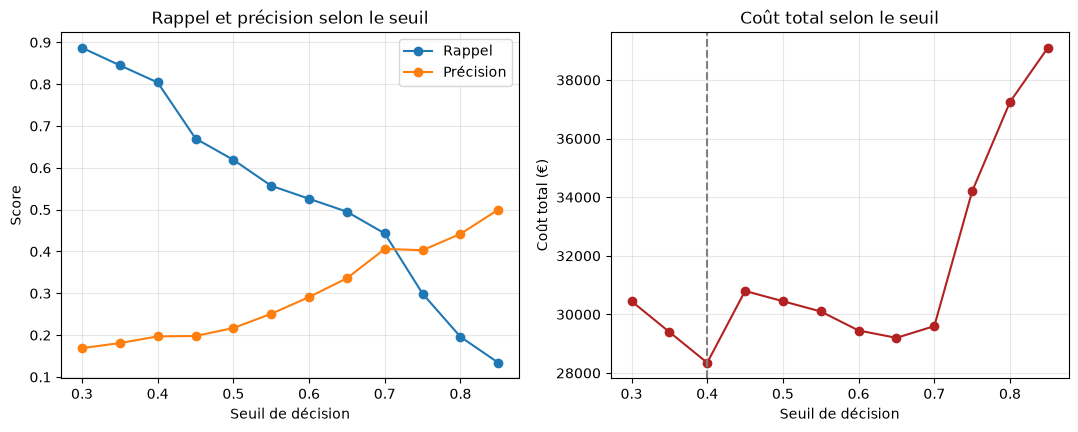

In [29]:
import matplotlib.pyplot as plt

probas = model.predict_proba(X_test)[:,1]

# Tableau
lignes = []
for seuil in np.arange(0.30, 0.86, 0.05):
    pred = (probas >= seuil).astype(int)
    vp = ((pred == 1) & (y_test == 1)).sum() # depart détecté
    fp = ((pred == 1) & (y_test == 0)).sum() # départ signalé à tort
    fn = ((pred == 0) & (y_test == 1)).sum() # départ manqué
    lignes.append({
    "seuil":round(seuil,2),
    "clients_signales": pred.sum(),
    "depart_detectes": vp,
    "fausses_alertes": fp,
    "depart_manques": fn,
    "rappel": round(vp / (vp + fn), 3),
    "precision": round(vp / (vp + fp), 3) if (vp + fp) > 0 else np.nan,
    })
resultats = pd.DataFrame(lignes)

# calcul du coût total selon le métier
cout_contact = 50 #coût d'un contact client en €
cout_depart_manque = 450 #perte estimée pour un départ en €
resultats["cout_total"] = (resultats["clients_signales"] * cout_contact
                           + resultats["depart_manques"] * cout_depart_manque)
print(resultats.to_string(index=False))

meilleur = resultats.loc[resultats["cout_total"].idxmin()]
print(f"\nSeuil le moins coûteux : {meilleur['seuil']} "
      f"(coût total : {meilleur['cout_total']:,.0f} €)")

# visualisation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(resultats["seuil"], resultats["rappel"], marker="o", label="Rappel")
ax1.plot(resultats["seuil"], resultats["precision"], marker="o", label="Précision")
ax1.set_xlabel("Seuil de décision"); ax1.set_ylabel("Score")
ax1.set_title("Rappel et précision selon le seuil"); ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(resultats["seuil"], resultats["cout_total"], marker="o", color="firebrick")
ax2.axvline(meilleur["seuil"], linestyle="--", color="grey")
ax2.set_xlabel("Seuil de décision"); ax2.set_ylabel("Coût total (€)")
ax2.set_title("Coût total selon le seuil"); ax2.grid(alpha=0.3)
plt.show()